## Задание 3: Подбор гиперпараметров


In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.inspection import permutation_importance
import optuna
import shap
import warnings

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
optuna.logging.set_verbosity(optuna.logging.WARNING)


## Данные


In [76]:
url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2022/2022-01-18/chocolate.csv'
df = pd.read_csv(url)

df['cocoa_percent'] = df['cocoa_percent'].str.rstrip('%').astype(float)
df['ingredients'] = df['ingredients'].fillna('Unknown')

target = df['rating'].copy()
numeric_features = ['cocoa_percent', 'review_date']
categorical_features = ['country_of_bean_origin', 'company_manufacturer', 'company_location']

X_numeric = df[numeric_features].copy()
X_categorical = pd.DataFrame()

for feature in categorical_features:
    le = LabelEncoder()
    df[feature] = df[feature].fillna('Unknown')
    X_categorical[feature] = le.fit_transform(df[feature])

X = pd.concat([X_numeric, X_categorical], axis=1)


In [77]:
X_train, X_test, y_train, y_test = train_test_split(X, target, test_size=0.2, random_state=RANDOM_STATE)


## GradientBoostingRegressor


GradientBoostingRegressor — ансамблевая модель, последовательно исправляющая ошибки деревьев. Улавливает нелинейные зависимости, устойчива к выбросам

**Оптимизируемые гиперпараметры:**
- `n_estimators` (50-500) — число деревьев
- `max_depth` (3-10) — глубина деревьев, контроль переобучения
- `learning_rate` (0.01-0.3) — скорость обучения
- `min_samples_split` (2-20) — регуляризация
- `subsample` (0.6-1.0) — доля выборки, стохастичность


In [78]:
def calculate_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

rmse_scorer = make_scorer(calculate_rmse, greater_is_better=False)


## RandomizedSearchCV


In [79]:
%%time

param_distributions = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [3, 4, 5, 6, 7],
    'learning_rate': [0.01, 0.05, 0.1, 0.15],
    'min_samples_split': [2, 5, 10],
    'subsample': [0.8, 0.9, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_distributions=param_distributions,
    n_iter=50,
    cv=5,
    scoring=rmse_scorer,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)

random_search.fit(X_train, y_train)


Fitting 5 folds for each of 50 candidates, totalling 250 fits
CPU times: user 904 ms, sys: 171 ms, total: 1.08 s
Wall time: 14 s


,estimator,GradientBoost...ndom_state=42)
,param_distributions,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [50, 100, ...], ...}"
,n_iter,50
,scoring,make_scorer(c...hod='predict')
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [80]:
best_params_rs = random_search.best_estimator_.get_params()
for param_name in sorted(param_distributions.keys()):
    print(f"{param_name}: {best_params_rs[param_name]}")
print(f"\nCV RMSE: {-random_search.best_score_:.4f}")


learning_rate: 0.05
max_depth: 3
min_samples_split: 10
n_estimators: 300
subsample: 0.8

CV RMSE: 0.4083


## Optuna


TPE sampler — байесовская оптимизация, использующая результаты предыдущих испытаний для выбора следующих параметров. Эффективнее random search. 100 испытаний для баланса времени и качества


In [81]:
%%time

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'random_state': RANDOM_STATE
    }
    
    model = GradientBoostingRegressor(**params)
    kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(model, X_train, y_train, cv=kfold, scoring=rmse_scorer, n_jobs=-1)
    
    return abs(scores.mean())

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=100, show_progress_bar=True)


  0%|          | 0/100 [00:00<?, ?it/s]

CPU times: user 1.51 s, sys: 177 ms, total: 1.69 s
Wall time: 1min 9s


In [82]:
for param_name in sorted(study.best_params.keys()):
    print(f"{param_name}: {study.best_params[param_name]}")
print(f"\nCV RMSE: {study.best_value:.4f}")


learning_rate: 0.020993569489162988
max_depth: 8
min_samples_split: 13
n_estimators: 154
subsample: 0.6300918918800937

CV RMSE: 0.4019


In [83]:
if abs(study.best_value) < -random_search.best_score_:
    best_params = study.best_params.copy()
    best_params['random_state'] = RANDOM_STATE
else:
    best_params = random_search.best_params_.copy()
    best_params['random_state'] = RANDOM_STATE


In [84]:
final_model = GradientBoostingRegressor(**best_params)
final_model.fit(X_train, y_train)


,loss,'squared_error'
,learning_rate,0.020993569489162988
,n_estimators,154
,subsample,0.6300918918800937
,criterion,'friedman_mse'
,min_samples_split,13
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,8
,min_impurity_decrease,0.0
,init,None


## Оценка


RMSE: 0.4191
R²: 0.1542


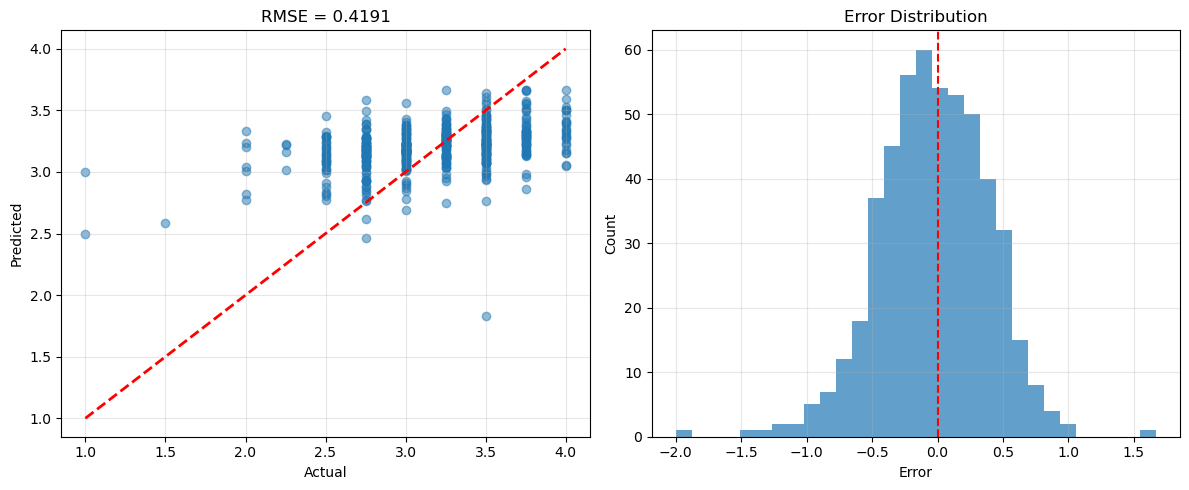

In [85]:
from sklearn.metrics import r2_score

y_pred = final_model.predict(X_test)
rmse_test = calculate_rmse(y_test, y_pred)
r2_test = r2_score(y_test, y_pred)

print(f"RMSE: {rmse_test:.4f}")
print(f"R²: {r2_test:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, y_pred, alpha=0.5)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].set_title(f'RMSE = {rmse_test:.4f}')
axes[0].grid(True, alpha=0.3)

errors = y_test - y_pred
axes[1].hist(errors, bins=30, alpha=0.7)
axes[1].axvline(x=0, color='r', linestyle='--')
axes[1].set_xlabel('Error')
axes[1].set_ylabel('Count')
axes[1].set_title('Error Distribution')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Интерпретация


**Permutation Importance** — снижение качества при перемешивании признака (n_repeats=10)

**SHAP** — значения Шепли, вклад признаков в предсказание. TreeExplainer для деревьев. Визуализации: bar plot, beeswarm, dependence plot

Сравнение двух методов повышает надежность выводов


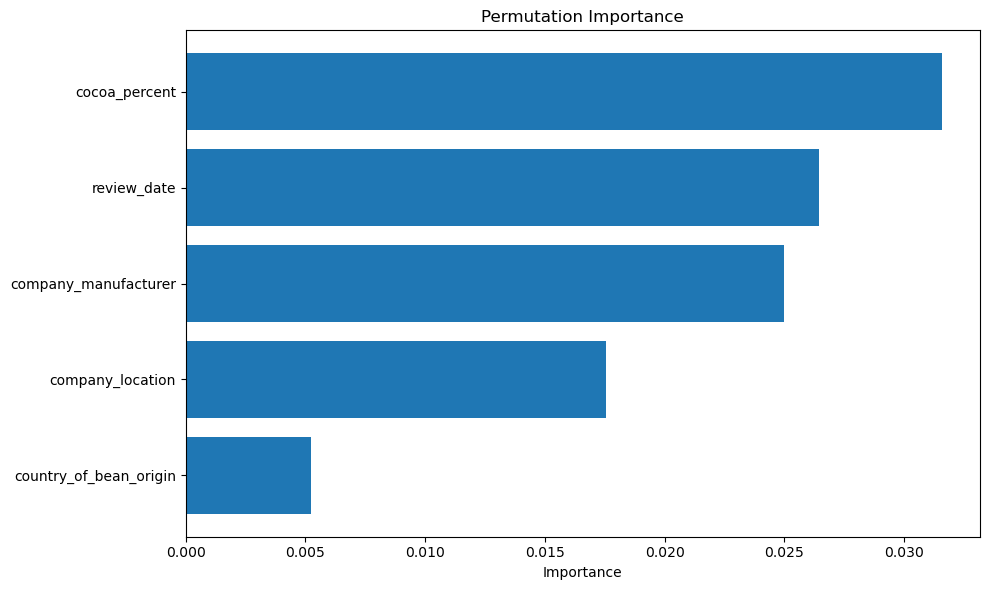

In [86]:
perm_importance = permutation_importance(
    final_model, X_test, y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'feature': X.columns,
    'importance_mean': perm_importance.importances_mean
}).sort_values('importance_mean', ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(importance_df['feature'], importance_df['importance_mean'])
ax.set_xlabel('Importance')
ax.set_title('Permutation Importance')
ax.invert_yaxis()
plt.tight_layout()
plt.show()


In [87]:
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test)

shap_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': np.abs(shap_values).mean(axis=0)
}).sort_values('importance', ascending=False)

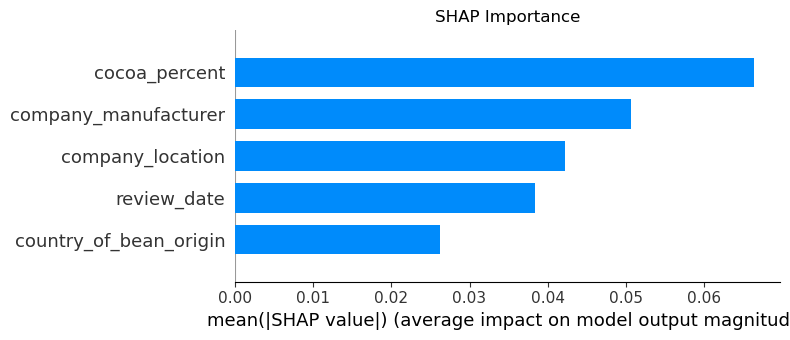

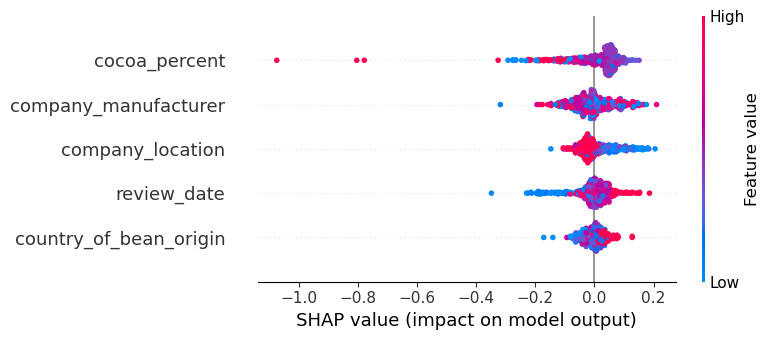

In [88]:
fig, ax = plt.subplots(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title('SHAP Importance')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.tight_layout()
plt.show()

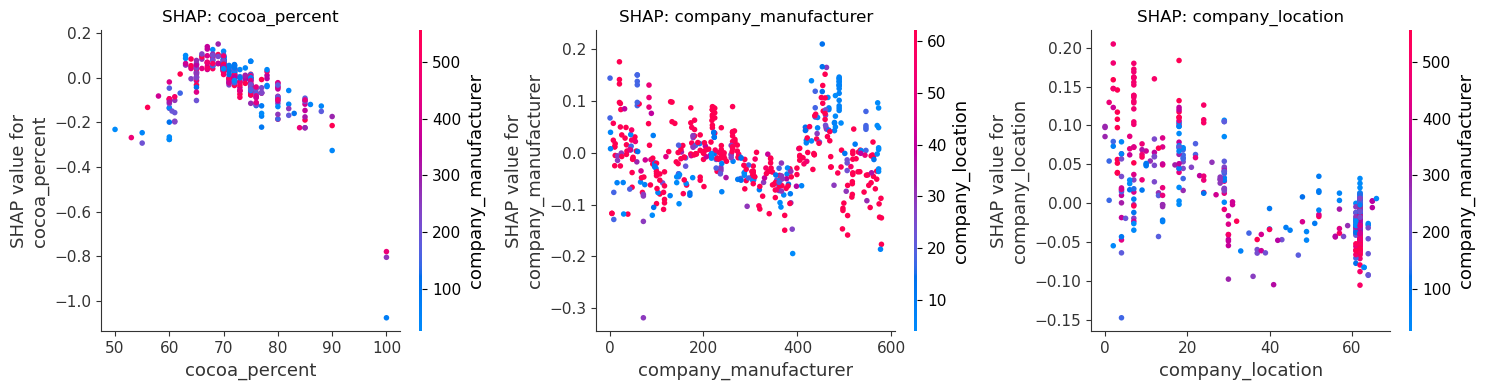

In [89]:
top_features = shap_importance.head(3)['feature'].tolist()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, feature in enumerate(top_features):
    feature_idx = X.columns.tolist().index(feature)
    shap.dependence_plot(feature_idx, shap_values, X_test, ax=axes[idx], show=False)
    axes[idx].set_title(f'SHAP: {feature}')

plt.tight_layout()
plt.show()

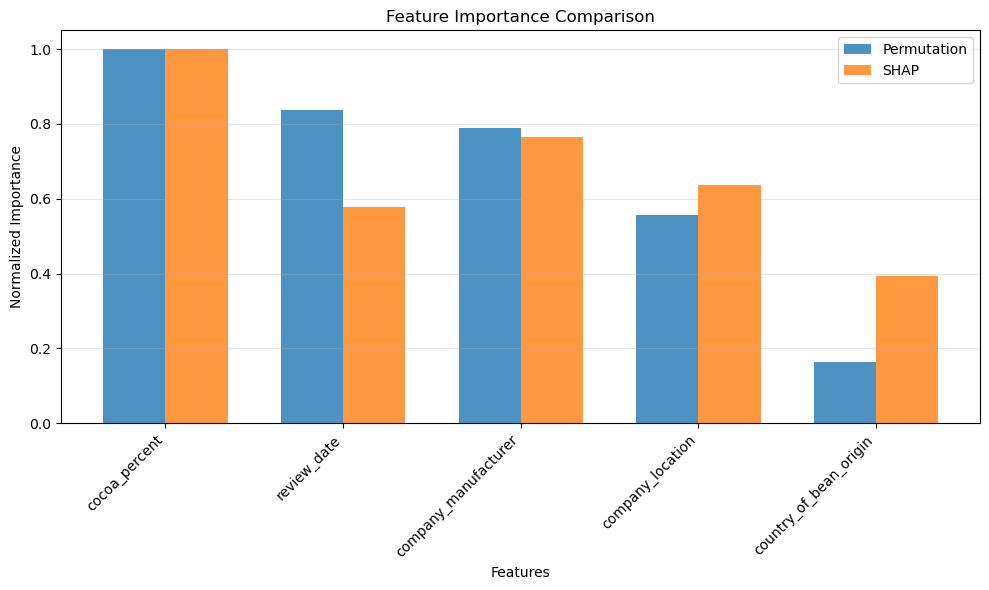

In [90]:
perm_norm = importance_df['importance_mean'] / importance_df['importance_mean'].max()
shap_norm = shap_importance.set_index('feature').loc[importance_df['feature']]['importance']
shap_norm = shap_norm / shap_norm.max()

comparison_df = pd.DataFrame({
    'feature': importance_df['feature'],
    'Permutation': perm_norm.values,
    'SHAP': shap_norm.values
}).sort_values('Permutation', ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(comparison_df))
width = 0.35

ax.bar(x - width/2, comparison_df['Permutation'], width, label='Permutation', alpha=0.8)
ax.bar(x + width/2, comparison_df['SHAP'], width, label='SHAP', alpha=0.8)

ax.set_xlabel('Features')
ax.set_ylabel('Normalized Importance')
ax.set_title('Feature Importance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['feature'], rotation=45, ha='right')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


## Экспертное мнение

**Результаты:**
- GradientBoostingRegressor: RMSE = 0.4191, R² = 0.1542
- Оптимизация: RandomizedSearchCV (RMSE 0.4083) → Optuna TPE (RMSE 0.4019)
- Интерпретация: Permutation Importance + SHAP (согласованные результаты)

**Наиболее важные признаки:**
1. **Процент какао** — ключевой фактор, влияющий на вкус и текстуру
2. **Производитель** — разные технологии и стандарты качества
3. **Год оценки** — возможно изменение стандартов оценки со временем

**Оценка:** Модель выявляет логичные зависимости, соответствующие экспертным знаниям о шоколадной индустрии.
